In [1]:
import numpy as np
import astropy.units as u
from lifesimmc.core.modules.processing.matched_filter_module import MatchedFilterModule
from matplotlib import pyplot as plt
from phringe.core.scene import Scene
from phringe.core.sources.local_zodi import LocalZodi

from scipy.stats import ncx2, norm
from matplotlib.colors import LogNorm, SymLogNorm


from lifesimmc.core.modules.generating.data_generation_module import DataGenerationModule
from lifesimmc.core.modules.generating.template_generation_module import TemplateGenerationModule
from lifesimmc.core.modules.loading.setup_module import SetupModule
from lifesimmc.core.modules.processing.energy_detector_test_module import EnergyDetectorTestModule
from lifesimmc.core.modules.processing.ml_parameter_estimation_module import MLSEDEstimationModule
from lifesimmc.core.modules.processing.neyman_pearson_test_module import NeymanPearsonTestModule
from lifesimmc.core.modules.processing.variance_normalization_module import NoiseVarianceNormalizationModule
from lifesimmc.core.modules.processing.zca_whitening_module import ZCAWhiteningModule 
from lifesimmc.core.modules.processing.highpass_filter_module import HighPassFilterModule

from setup.prototype_setup import inst, obs
from lifesimmc.core.pipeline import Pipeline
from lifesimmc.lib.colormaps import cmap_blue

rad_to_as = 3600*180/np.pi


In [2]:
#from setup.config.kap_and import star, kap_and_b, exozodi

# Beta  Pic
from setup.spectra.BetaPic.bet_pic import star, bet_pic_b, exozodi 
planet = bet_pic_b.model_copy()

# HR 8799 
#from setup.spectra.HR8799.hr_8799 import star, hr_8799_c, exozodi 
#planet = hr_8799_c.model_copy()

# Save all plots / results in the folder of the target's input spectrum
from pathlib import Path
out_dir = Path(planet.sed_loader.path_to_file).parent

In [3]:
from matplotlib.patches import Ellipse

def plot_covariance_ellipse(cov, mean=(0, 0), n_stds=[2.0], ax=None, **kwargs):
    """
    Plots a confidence ellipse based on a 2D covariance matrix.
    """
    if ax is None:
        ax = plt.gca()

    # 1. Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    
    # Sort eigenvalues/vectors to find the major and minor axes consistently
    order = eigenvalues.argsort()[::-1]
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
    
    # 2. Calculate the angle of rotation (in degrees)
    # The first eigenvector corresponds to the major axis
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    
    # 3. Calculate width and height based on the standard deviation
    # Eigenvalues represent variance, so take the square root for standard deviation
    width, height = 2 * np.sqrt(eigenvalues)
    
    # 4. Create and add the ellipse patch
    for n_std in n_stds:
        ellipse = Ellipse(xy=mean, width=n_std*width, height=n_std*height, angle=angle, **kwargs )
        ax.add_patch(ellipse)
    
    return ellipse

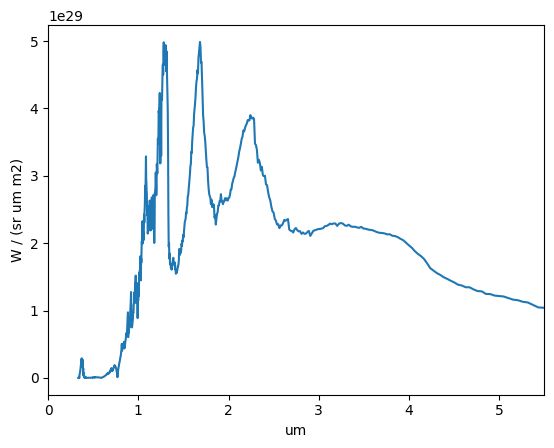

In [4]:
plt.plot(1e6*planet.sed_loader.wavelengths, planet.sed_loader.sed)
plt.xlabel(planet.sed_loader.wavelength_units)
plt.ylabel(planet.sed_loader.sed_units)
plt.xlim(0,5.5)
plt.savefig(Path(planet.sed_loader.path_to_file).with_suffix('.png'), transparent = True, dpi = 300)

In [5]:
scene = Scene()
# Create local zodi
local_zodi = LocalZodi()


# Add sources to scene
scene.add_source(star)
scene.add_source(local_zodi)
scene.add_source(exozodi)
scene.add_source(planet)

In [6]:
# Create the pipeline
pipeline = Pipeline(gpu_index=2, grid_size=60) # seed=42,


# Setup the simulation
module = SetupModule(
    n_setup_out='setup',
    n_planets_out='params_init',
    instrument=inst,
    observation=obs,
    scene=scene
)
pipeline.add_module(module)


pipeline.run()

wavelengths = inst._get_wavelength_bins()[0] * 1e6
temp_fov = max(inst._field_of_view) * rad_to_as /2

Loading setup...
Done


In [7]:
module = DataGenerationModule(n_setup_in='setup', n_data_out='data')
pipeline.add_module(module)


module = TemplateGenerationModule(n_setup_in='setup', n_template_out='temp', fov=max(inst._field_of_view)/2)

pipeline.add_module(module)

module = HighPassFilterModule(
                n_data_in='data',
                n_template_in='temp',
                n_data_out='data_filtered',
                n_template_out='temp_filtered',
                n_transformation_out='highpass',
                n_frequencies=1,
            )
pipeline.add_module(module)


module = ZCAWhiteningModule(
                n_setup_in='setup',
                n_data_in='data',
                n_template_in='temp',
                n_data_out='data_filtered_white',
                n_template_out='temp_filtered_white',
                n_transformation_out='zca_filtered',
                diagonal_only=True,
                subtract_mean=True
            )
pipeline.add_module(module)


pipeline.run()

Output()

Done
Generating templates...
Done
Applying high-pass filter...
Done
Applying ZCA whitening...
condition number of cov matrix tensor(6.7770)
Done


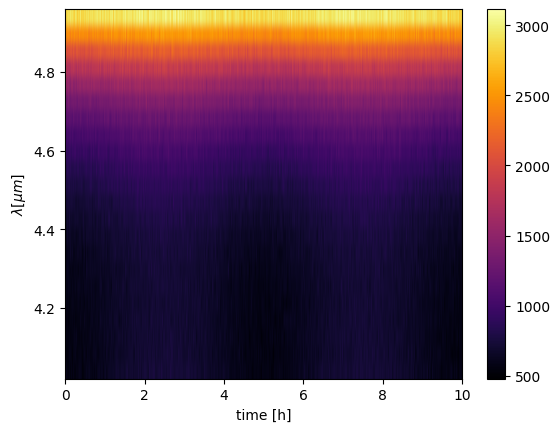

In [8]:
data = pipeline.get_resource('data').get_data()[0]

plt.figure()
plt.imshow(data,  cmap='inferno', origin = 'lower',  extent = [0, obs.total_integration_time/3600, min(wavelengths), max(wavelengths)], aspect = 'auto')
plt.colorbar()
plt.xlabel("time [h]")
plt.ylabel(r"$\lambda [\mu m]$")
plt.savefig(out_dir / "data.png", transparent = True, dpi = 300)
plt.show()
plt.close()



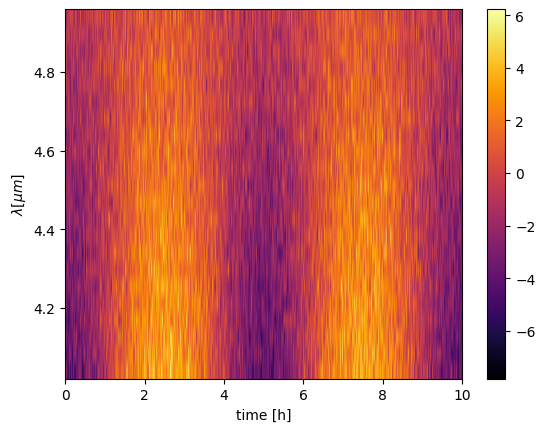

In [9]:
data = pipeline.get_resource('data_filtered_white').get_data()[0]


plt.figure()
plt.imshow(data,  cmap='inferno', origin = 'lower',  extent = [0, obs.total_integration_time/3600, min(wavelengths), max(wavelengths)], aspect = 'auto')
plt.colorbar()
plt.xlabel("time [h]")
plt.ylabel(r"$\lambda [\mu m]$")
plt.savefig(out_dir / "data_filtered_white.png", transparent = True, dpi = 300)
plt.show()
plt.close()



In [10]:
'''
# Generate the correlation map
module = MatchedFilterModule(n_data_in='data_filtered_white', n_template_in='temp_filtered_white', n_image_out='imag_corr')
pipeline.add_module(module)
pipeline.run()

# Get the correlation map from the image resource
imag_corr = pipeline.get_resource('imag_corr').get_image(as_numpy=True)

# Plot the image
#plt.contourf(imag_corr, cmap=cmap_blue)
plt.imshow(imag_corr, extent=(-temp_fov/2, temp_fov/2, -temp_fov/2, temp_fov/2))
plt.colorbar()
#plt.savefig(out_dir / "corr_map_white.png", transparent = True, dpi = 300)
plt.show()
plt.close()
'''

'\n# Generate the correlation map\nmodule = MatchedFilterModule(n_data_in=\'data_filtered_white\', n_template_in=\'temp_filtered_white\', n_image_out=\'imag_corr\')\npipeline.add_module(module)\npipeline.run()\n\n# Get the correlation map from the image resource\nimag_corr = pipeline.get_resource(\'imag_corr\').get_image(as_numpy=True)\n\n# Plot the image\n#plt.contourf(imag_corr, cmap=cmap_blue)\nplt.imshow(imag_corr, extent=(-temp_fov/2, temp_fov/2, -temp_fov/2, temp_fov/2))\nplt.colorbar()\n#plt.savefig(out_dir / "corr_map_white.png", transparent = True, dpi = 300)\nplt.show()\nplt.close()\n'

In [11]:
module = MLSEDEstimationModule(
    n_setup_in='setup',
    n_data_in='data_filtered_white',
    n_template_in='temp_filtered_white',
    n_transformation_in='zca_filtered',
    #n_planets_in='params_init',
    n_planets_out='params_ml',
)

pipeline.add_module(module)
pipeline.run()



# Get the initial (input) parameters so we can plot the input spectrum (spectral energy distribution; SED) as a reference
params_init = pipeline.get_resource('params_init')
params_ml = pipeline.get_resource('params_ml')

# SED error for marginalised position
sed_estimated = params_ml.collection[0].sed 
sed_err = params_ml.collection[0].std

# Full covariance (fluxes + position) for the free-position fit
full_cov = params_ml.collection[0].cov

x_est, y_est = params_ml.collection[0].pos_x, params_ml.collection[0].pos_y
phi = np.arctan2(y_est, x_est)

rotation_mat = np.identity(full_cov.shape[0])
rotation_mat[-2,-2] = np.cos(phi)
rotation_mat[-1,-1] = np.cos(phi)
rotation_mat[-2,-1] = np.sin(phi)
rotation_mat[-1,-2] = -np.sin(phi)

full_cov_diag = rotation_mat @ full_cov @ rotation_mat.T
wavelengths = inst._get_wavelength_bins()[0] * 1e6


sed_init_observed = planet.spectral_energy_distribution[:, 0, 0].cpu().numpy()



Output()

Done


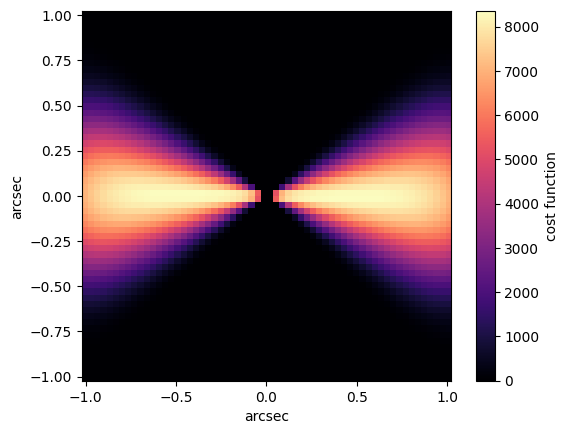

In [12]:
plt.imshow(module.cost_function, cmap='magma', extent=(-temp_fov/2, temp_fov/2, -temp_fov/2, temp_fov/2))
plt.xlabel("arcsec")
plt.ylabel('arcsec')
plt.colorbar(label = 'cost function')
plt.savefig(out_dir / "cost_function.png", transparent = True, dpi = 300)
plt.show()
plt.close()

In [13]:
# ===================== Known-Position Fit ==================
# Refit only the fluxes with the position fixed at the true planet position (taken from params_init). The SED and
# covariance are then conditional on the known position -- the correct 'known position' estimate and error bars.
module_fix = MLSEDEstimationModule(
    n_setup_in='setup',
    n_data_in='data_filtered_white',
    n_template_in='temp_filtered_white',
    n_transformation_in='zca_filtered',
    n_planets_in='params_init',
    n_planets_out='params_ml_fix',
    fix_position=True,
)

pipeline.add_module(module_fix)
pipeline.run()

params_ml_fix = pipeline.get_resource('params_ml_fix')
sed_estimated_fix = params_ml_fix.collection[0].sed
sed_err_fix = params_ml_fix.collection[0].std
cov_fix = params_ml_fix.collection[0].cov  # n_wavelengths x n_wavelengths (fluxes only)


Output()

Done


In [20]:
import io, contextlib
from scipy.stats import chi2 as chi2_dist

# ===================== Metrics =====================
# Computed once here and reused in the plots below.
positions = np.asarray(planet._get_proj_sky_pos() / star.distance)

# Position precision and accuracy
pos_est = np.array([x_est, y_est])
pos_true = np.array([positions[1,-1], positions[0,-1]])
full_data = np.append(sed_estimated, pos_est)
full_data_diag = rotation_mat @ full_data
cov_pos = full_cov_diag[-2:,-2:]

snr_radius = full_data_diag[-2] / np.sqrt(cov_pos[0,0])                 # r / sigma_r
snr_angle = 2 * np.pi * full_data_diag[-2] / np.sqrt(cov_pos[-1,-1])    # 2 pi / sigma_phi

r_dif_m = pos_true - pos_est
r_dif_p = pos_true + pos_est
sig_p = np.sqrt(1/2*r_dif_p @ np.linalg.inv(full_cov[-2:,-2:]) @ r_dif_p)
sig_m = np.sqrt(1/2*r_dif_m @ np.linalg.inv(full_cov[-2:,-2:]) @ r_dif_m)
pos_accuracy = min(sig_p, sig_m)

# Flux SNR and goodness of fit (sqrt(chi^2 / n), should be ~1)
cov_marg = full_cov[:-2, :-2]
res_fix = sed_estimated_fix - sed_init_observed
res_marg = sed_estimated - sed_init_observed
snr_known = np.sqrt(sed_estimated_fix @ np.linalg.inv(cov_fix) @ sed_estimated_fix)
snr_marg = np.sqrt(sed_estimated @ np.linalg.inv(cov_marg) @ sed_estimated)
dev_known = np.sqrt(1/len(res_fix) * res_fix @ np.linalg.inv(cov_fix) @ res_fix)
dev_marg = np.sqrt(1/len(res_marg) * res_marg @ np.linalg.inv(cov_marg) @ res_marg)

# Residual per eigenmode of the marginalised flux covariance: each z_k is independent N(0, 1) if the error model is
# right, and chi^2 = sum_k z_k^2. A coherent offset of all channels shows up as one large |z| in the largest-variance
# mode (which looks like a scaled copy of the spectrum), while the other modes scatter normally.
eigval, eigvec = np.linalg.eigh(cov_marg)          # ascending order -> last mode has the largest variance
z_modes = eigvec.T @ res_marg / np.sqrt(eigval)
mode_spectrum_corr = abs(np.corrcoef(eigvec[:, -1], sed_init_observed)[0, 1])
chi2_total = np.sum(z_modes**2)
p_chi2_total = chi2_dist.sf(chi2_total, len(z_modes))
p_mode_scale = chi2_dist.sf(z_modes[-1]**2, 1)

snr_buffer = io.StringIO()
with contextlib.redirect_stdout(snr_buffer):
    print("Measurement of the Precision of the position")
    print("============ Precision of the radius (r / sigma_r) =========")
    print(f'{snr_radius:.3f}')
    print("============ Precision of the angle (2 pi / sigma_phi) =========")
    print(f'{snr_angle:.4f}', "")
    print("============ Accuracy of the position estimate ~ 0.886 =========")
    print(f'{pos_accuracy:.2f} sigma')

    print("\nMeasurement of the Precision of the flux")
    print("============ Bulk SNR on the flux (known position) =========")
    print(f'{snr_known:.2f}')
    print("============ Bulk SNR on the flux (marg. position) =========")
    print(f'{snr_marg:.2f}')

    print("\n Accuracy of the flux / Goodness of fit \n < 1: overfitting, overestimated the errorbar \n > 1: not fitted well, underestimated the error bar")
    print("============ Mean Deviation from the flux (known position) (should be ~1)=========")
    print(f'{dev_known:.2f}')
    print("============ Mean Deviation of the flux (marg. position) (should be ~1) =========")
    print(f'{dev_marg:.2f}')

    # chi^2 split into the largest-variance (overall flux scale) mode and the rest
    print("============ chi^2 breakdown (marg. position) =========")
    print(f'total chi^2 = {chi2_total:.1f} for {len(z_modes)} channels (p = {p_chi2_total:.3f})')
    print(f'largest-variance mode: z = {z_modes[-1]:.2f} sigma -> chi^2 = {z_modes[-1]**2:.1f}, '
          f'p(1 dof) = {p_mode_scale:.3f}; corr. with spectrum shape = {mode_spectrum_corr:.2f}')
    print(f'remaining {len(z_modes) - 1} modes: chi^2 = {np.sum(z_modes[:-1]**2):.1f}')

print(snr_buffer.getvalue())
(out_dir / "snr_summary.txt").write_text(snr_buffer.getvalue())


Measurement of the Precision of the position
============ Precision of the radius (r / sigma_r) =========
23.417
============ Precision of the angle (2 pi / sigma_phi) =========
2293.2829 
============ Accuracy of the position estimate ~ 0.886 =========
0.91 sigma

Measurement of the Precision of the flux
============ Bulk SNR on the flux (known position) =========
181.89
============ Bulk SNR on the flux (marg. position) =========
21.96

 Accuracy of the flux / Goodness of fit 
 < 1: overfitting, overestimated the errorbar 
 > 1: not fitted well, underestimated the error bar
============ Mean Deviation from the flux (known position) (should be ~1)=========
0.77
============ Mean Deviation of the flux (marg. position) (should be ~1) =========
0.88
============ chi^2 breakdown (marg. position) =========
total chi^2 = 16.9 for 22 channels (p = 0.770)
largest-variance mode: z = -1.39 sigma -> chi^2 = 1.9, p(1 dof) = 0.164; corr. with spectrum shape = 0.94
remaining 21 modes: chi^2 = 14.9


1000

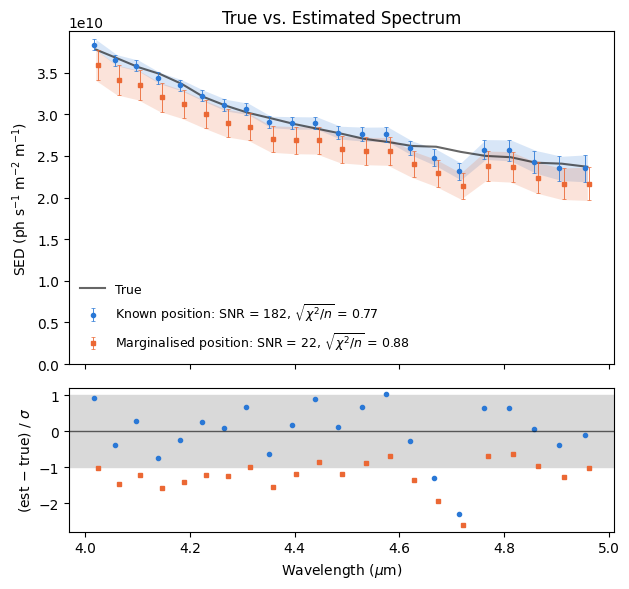

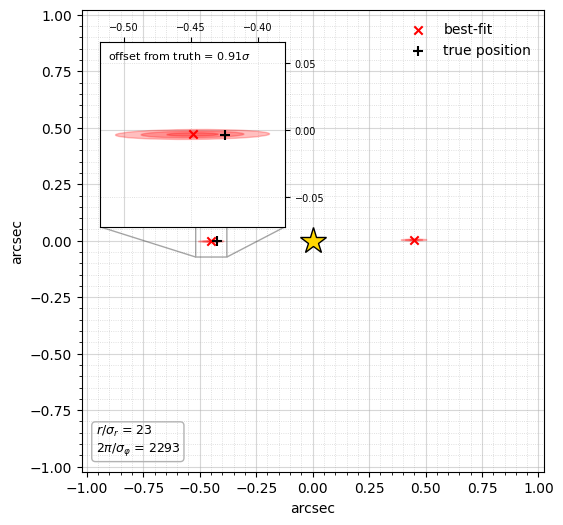

In [32]:
# ===================== Flux Plot ==================

# Known position (blue, circles) and marginalised position (orange, squares) on one figure. The lower panel shows
# the residual of each channel in units of its own 1-sigma error bar.
flux_cases = [
    (sed_estimated_fix, sed_err_fix, rf'Known position: SNR = {snr_known:.0f}, $\sqrt{{\chi^2/n}}$ = {dev_known:.2f}',
     '#2a78d6', 'o', -0.004),
    (sed_estimated, sed_err, rf'Marginalised position: SNR = {snr_marg:.0f}, $\sqrt{{\chi^2/n}}$ = {dev_marg:.2f}',
     '#eb6834', 's', +0.004),
]

fig, (ax, ax_res) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 6), gridspec_kw={'height_ratios': [3, 1.3]})
ax.plot(wavelengths, sed_init_observed, label='True', linestyle='-', color='black', alpha=0.6, zorder=1)

for sed_plot, err_plot, label, color, marker, dx in flux_cases:
    # small wavelength offset so the two sets of error bars don't sit on top of each other
    ax.errorbar(wavelengths + dx, sed_plot, yerr=err_plot, fmt=marker, markersize=3, color=color,
                ecolor=color, elinewidth=0.6, capsize=1.5, capthick=0.5, label=label, zorder=3)
    ax.fill_between(wavelengths, sed_plot - err_plot, sed_plot + err_plot, color=color, lw=0, alpha=0.18, zorder=0)
    ax_res.plot(wavelengths + dx, (sed_plot - sed_init_observed) / err_plot, marker, markersize=3, color=color)

ax.set_ylabel(r'SED (ph s$^{-1}$ m$^{-2}$ m$^{-1}$)')
ax.set_ylim(bottom=0)
ax.set_title('True vs. Estimated Spectrum')
ax.legend(loc="lower left", framealpha=0., fontsize=9)

ax_res.axhline(0, color='black', alpha=0.6, lw=1)
ax_res.axhspan(-1, 1, color='0.85', zorder=0)
ax_res.set_ylabel(r'(est $-$ true) / $\sigma$')
ax_res.set_xlabel(r'Wavelength ($\mu $m)')

fig.tight_layout()
plt.savefig(out_dir / "flux_estimate.png", transparent = True, dpi = 300)
plt.show()
plt.close()




# ================= Position Estimate (full field with inset zoom) =====================
cov_pos_as = full_cov[-2:,-2:] * rad_to_as**2

# The instrument has an exact +/-(x,y) position ambiguity, so the best-fit can land on either the true position or
# its mirror image. Pick whichever true-position candidate is closer to the best fit for the zoom.
true_x_same, true_y_same = positions[1,-1], positions[0,-1]
true_x_flip, true_y_flip = -positions[1,-1], -positions[0,-1]
dist_same = (x_est - true_x_same)**2 + (y_est - true_y_same)**2
dist_flip = (x_est - true_x_flip)**2 + (y_est - true_y_flip)**2
true_x, true_y = (true_x_same, true_y_same) if dist_same <= dist_flip else (true_x_flip, true_y_flip)

# Square zoom window (equal aspect, so it is a true magnification) containing the 3-sigma ellipse and the true position
xc, yc = x_est * rad_to_as, y_est * rad_to_as
half_3sig = 3 * np.sqrt(np.linalg.eigvalsh(cov_pos_as).max())
half_zoom = 1.2 * max(half_3sig, abs(true_x * rad_to_as - xc), abs(true_y * rad_to_as - yc))

fig, ax = plt.subplots(figsize=(6, 6))
# Inset on the planet's side (above it), so the connector lines stay short and don't cross the star
zoom_left = 0.04 if xc < 0 else 0.55
inset_bounds = [zoom_left, 0.53, 0.40, 0.40]   # in axes fraction
ax_zoom = ax.inset_axes(inset_bounds)

for a in (ax, ax_zoom):
    for sign in (1, -1):
        plot_covariance_ellipse(cov_pos_as, mean=(sign * xc, sign * yc), ax=a, alpha=0.25, color='r', n_stds=[1, 2, 3])
    a.scatter([xc, -xc], [yc, -yc], marker='x', color='r', label='best-fit', zorder=3)
    a.scatter(true_x * rad_to_as, true_y * rad_to_as, c='k', marker='+', s=60, label='true position', zorder=4)
    a.set_aspect('equal')

# Full field of view
ax.plot(0, 0, marker='*', color='gold', markersize=20, markeredgecolor='k')
ax.set_xlim(-temp_fov/2, temp_fov/2)
ax.set_ylim(-temp_fov/2, temp_fov/2)
ax.set_xlabel('arcsec')
ax.set_ylabel('arcsec')
ax.legend(loc="upper right" if xc < 0 else "upper left", framealpha=0., fontsize=10)
ax.text(0.03, 0.03,
        rf'$r/\sigma_r$ = {snr_radius:.0f}' + '\n' + rf'$2\pi/\sigma_\varphi$ = {snr_angle:.0f}',
        transform=ax.transAxes, va='bottom', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='none', edgecolor='0.7'))

# Inset zoom with box + connector lines
ax_zoom.set_xlim(xc - half_zoom, xc + half_zoom)
ax_zoom.set_ylim(yc - half_zoom, yc + half_zoom)
ax_zoom.tick_params(labelsize=7)
# tick labels on the top/right edges of the inset so they don't collide with the main axis labels or the zoom box
ax_zoom.xaxis.tick_top()
ax_zoom.yaxis.tick_right()
ax_zoom.xaxis.set_major_locator(plt.MaxNLocator(3))
ax_zoom.yaxis.set_major_locator(plt.MaxNLocator(3))
#ax_zoom.text(0.04, 0.04, f'{2 * half_zoom * 1e3:.0f} mas wide', transform=ax_zoom.transAxes, va='bottom', fontsize=8)
ax_zoom.text(0.04, 0.96, f'offset from truth = {pos_accuracy:.2f}$\\sigma$', transform=ax_zoom.transAxes, va='top', fontsize=8)
ax.indicate_inset_zoom(ax_zoom, edgecolor='0.3')

# One grid (major + dotted minor subgrid) defined by the full field, drawn identically in the zoom: every line in the
# inset is the same sky line, with the same style, as in the full field -- the zoom only magnifies it.
grid_major = dict(color=plt.rcParams['grid.color'], linewidth=plt.rcParams['grid.linewidth'], alpha=0.5, linestyle='-')
grid_minor = dict(color='0.6', linewidth=0.6, alpha=0.4, linestyle=':')
from matplotlib.ticker import AutoMinorLocator
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.collections import LineCollection

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# The inset is transparent, so in the full field the grid is clipped to exclude the inset area
# (the axes rectangle with the inset cut out as a hole)
x0, y0, w, h = inset_bounds
outer = Path([(0, 0), (1, 0), (1, 1), (0, 1), (0, 0)], closed=True)
hole = Path([(x0, y0), (x0, y0 + h), (x0 + w, y0 + h), (x0 + w, y0), (x0, y0)], closed=True)  # opposite winding
grid_clip = PathPatch(Path.make_compound_path(outer, hole), transform=ax.transAxes, facecolor='none', edgecolor='none')
ax.add_patch(grid_clip)

xlim, ylim = ax.get_xlim(), ax.get_ylim()
for xlocs, ylocs, style in ((ax.get_xticks(), ax.get_yticks(), grid_major),
                            (ax.xaxis.get_minorticklocs(), ax.yaxis.get_minorticklocs(), grid_minor)):
    segs = [[(x, ylim[0]), (x, ylim[1])] for x in xlocs if xlim[0] <= x <= xlim[1]] \
         + [[(xlim[0], y), (xlim[1], y)] for y in ylocs if ylim[0] <= y <= ylim[1]]
    for a, clip in ((ax, grid_clip), (ax_zoom, None)):     # the inset clips to its own frame
        grid_lines = LineCollection(segs, colors=style['color'], linewidths=style['linewidth'], alpha=style['alpha'],
                                    linestyles=style['linestyle'], zorder=0.5)
        if clip is not None:
            grid_lines.set_clip_path(clip)
        a.add_collection(grid_lines, autolim=False)

plt.savefig(out_dir / "position_estimate.png", transparent = True, dpi = 300)
plt.show()
plt.close()
